# 06 - Métricas de Desempenho

Avaliação no conjunto de teste dos três modelos treinados nos notebooks 05:

1. CNN (`05_cnn_classification.ipynb` → `models/modelo_cnn.keras`)
2. FCNN (`05_fcnn_classification.ipynb` → `models/modelo_fcnn.keras`)
3. Encoder-Decoder (`05_encoder_decoder_classification.ipynb` → `models/modelo_encdec.keras`)

Para cada modelo: métricas de classificação, matriz de confusão, curvas ROC e Precision-Recall e análise dos erros. No final, uma tabela compara os três modelos.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             accuracy_score, precision_score, recall_score, f1_score)
from sklearn.preprocessing import label_binarize

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

I0000 00:00:1795092374.116669   56864 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Carregamento do conjunto de teste

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
teste = splits[splits['conjunto'] == 'teste'].reset_index(drop=True)

X_test, y_true = [], []
for _, row in teste.iterrows():
    caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
    img = Image.open(caminho).convert('RGB').resize((224, 224))
    X_test.append(np.array(img) / 255.0)
    y_true.append(classes.index(row['classe']))
X_test = np.array(X_test, dtype='float32')
y_true = np.array(y_true)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])

print(classes, X_test.shape)

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL'] (20, 224, 224, 3)


## Funções de avaliação

As mesmas funções são usadas para os três modelos.

In [3]:
def prever(arquivo):
    model = tf.keras.models.load_model(PROJECT_ROOT / 'models' / arquivo)
    return model.predict(X_test, verbose=0)


def metricas(y_pred):
    print(classification_report(y_true, y_pred, target_names=classes, zero_division=0))
    relatorio = classification_report(y_true, y_pred, target_names=classes, zero_division=0, output_dict=True)
    return pd.DataFrame(relatorio).T.round(2)


def matriz_confusao(y_pred, titulo):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Classe Prevista')
    plt.ylabel('Classe Real')
    plt.title(f'Matriz de Confusão: {titulo}')
    plt.show()


def curvas_roc_pr(y_pred_prob, titulo):
    print('ROC-AUC global:', round(roc_auc_score(y_true_bin, y_pred_prob, multi_class='ovr'), 4))
    print('PR-AUC global: ', round(average_precision_score(y_true_bin, y_pred_prob), 4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for i, classe in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
        axes[0].plot(fpr, tpr, label=classe)
        precisao, recall, _ = precision_recall_curve(y_true_bin[:, i], y_pred_prob[:, i])
        axes[1].plot(recall, precisao, label=classe)
    axes[0].plot([0, 1], [0, 1], 'k--')
    axes[0].set_title(f'Curva ROC: {titulo}')
    axes[0].set_xlabel('Taxa de Falsos Positivos')
    axes[0].set_ylabel('Taxa de Verdadeiros Positivos')
    axes[0].legend()
    axes[1].set_title(f'Curva Precision-Recall: {titulo}')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precisão')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    return pd.DataFrame({
        'ROC-AUC': roc_auc_score(y_true_bin, y_pred_prob, average=None),
        'PR-AUC': average_precision_score(y_true_bin, y_pred_prob, average=None),
    }, index=classes).round(2)


def analise_erros(y_pred_prob):
    y_pred = np.argmax(y_pred_prob, axis=1)

    resultado = pd.DataFrame(y_pred_prob.round(2), columns=classes)
    resultado.insert(0, 'arquivo', teste['caminho'].str.split('/').str[-1])
    resultado.insert(1, 'real', [classes[i] for i in y_true])
    resultado.insert(2, 'prevista', [classes[i] for i in y_pred])
    prob_ordenada = np.sort(y_pred_prob, axis=1)
    resultado['diferenca_top2'] = (prob_ordenada[:, -1] - prob_ordenada[:, -2]).round(2)

    erros = resultado[resultado['real'] != resultado['prevista']]
    print(f'Imagens classificadas incorretamente: {len(erros)} de {len(resultado)}')
    display(erros)

    # Falso Positivo da classe X: previsto como X, mas era outra classe.
    # Falso Negativo da classe X: era X, mas foi previsto como outra classe.
    print('Falsos Positivos e Falsos Negativos por classe:')
    display(pd.DataFrame({
        'Falsos Positivos': [((y_pred == i) & (y_true != i)).sum() for i in range(4)],
        'Falsos Negativos': [((y_true == i) & (y_pred != i)).sum() for i in range(4)],
    }, index=classes))

    # Casos ambíguos: as duas maiores probabilidades diferem menos de 0.15.
    print('Casos ambíguos (diferença entre as duas maiores probabilidades < 0.15):')
    display(resultado[resultado['diferenca_top2'] < 0.15])

    n = min(6, len(erros))
    if n > 0:
        fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
        for ax, idx in zip(np.atleast_1d(axes), erros.index[:n]):
            ax.imshow(X_test[idx])
            ax.set_title(f"Real: {resultado.loc[idx, 'real']}\nPrevista: {resultado.loc[idx, 'prevista']}", fontsize=9)
            ax.axis('off')
        plt.tight_layout()
        plt.show()

# 1. CNN

In [4]:
prob_cnn = prever('modelo_cnn.keras')
pred_cnn = np.argmax(prob_cnn, axis=1)

E0000 00:00:1795092375.758457   56864 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
I0000 00:00:1795092375.758480   56864 cuda_diagnostics.cc:160] env: CUDA_VISIBLE_DEVICES=""
I0000 00:00:1795092375.758488   56864 cuda_diagnostics.cc:163] CUDA_VISIBLE_DEVICES is set to an empty string - this hides all GPUs from CUDA
I0000 00:00:1795092375.758496   56864 cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
I0000 00:00:1795092375.758498   56864 cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: aquario
I0000 00:00:1795092375.758501   56864 cuda_diagnostics.cc:183] hostname: aquario
I0000 00:00:1795092375.758596   56864 cuda_diagnostics.cc:190] libcuda reported version is: 580.178.4
I0000 00:00:1795092375.758614   56864 cuda_diagnostics.cc:194] ke

I0000 00:00:1795092376.246895   56968 service.cc:153] XLA service 0x704548033140 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795092376.246909   56968 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1795092376.252389   56968 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


I0000 00:00:1795092376.723238   56968 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1795092376.724169   56968 cpu_allocator_impl.cc:82] Allocation of 157708800 exceeds 10% of free system memory.


## Acurácia, Precisão, Recall e F1-Score

In [5]:
metricas(pred_cnn)

              precision    recall  f1-score   support

       ICTAL       0.10      0.20      0.13         5
      NORMAL       0.17      0.20      0.18         5
   POS_ICTAL       0.00      0.00      0.00         5
   PRE_ICTAL       0.00      0.00      0.00         5

    accuracy                           0.10        20
   macro avg       0.07      0.10      0.08        20
weighted avg       0.07      0.10      0.08        20



,precision,recall,f1-score,support
ICTAL,0.10,0.2,0.13,5.0
NORMAL,0.17,0.2,0.18,5.0
POS_ICTAL,0.00,0.0,0.00,5.0
PRE_ICTAL,0.00,0.0,0.00,5.0
accuracy,0.10,0.1,0.10,0.1
macro avg,0.07,0.1,0.08,20.0
weighted avg,0.07,0.1,0.08,20.0


## Matriz de confusão

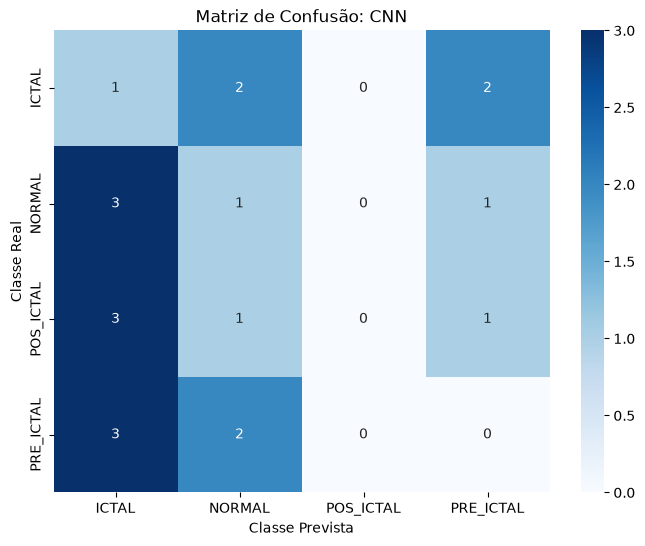

In [6]:
matriz_confusao(pred_cnn, 'CNN')

## Curvas ROC e Precision-Recall

ROC-AUC global: 0.5
PR-AUC global:  0.347


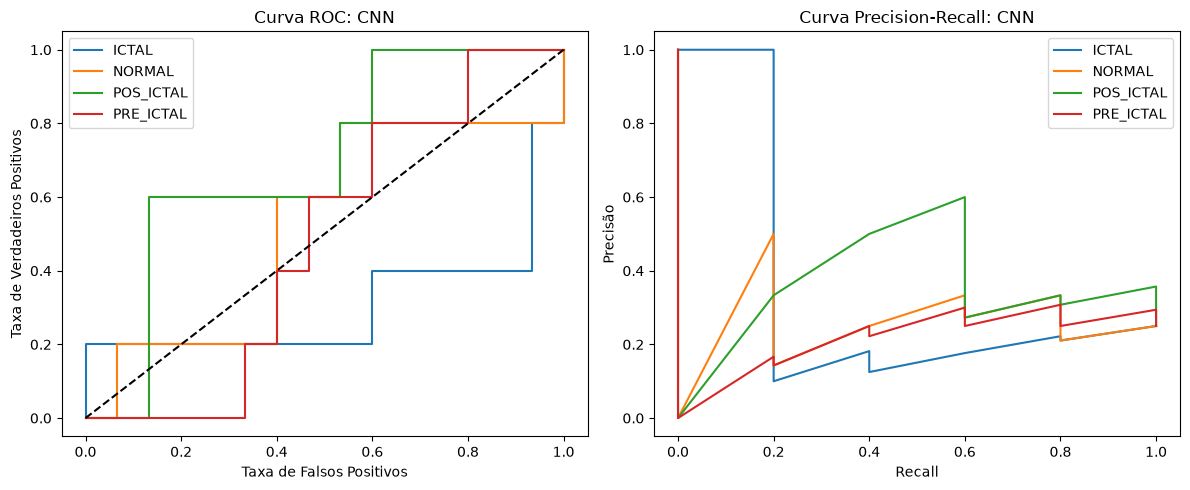

,ROC-AUC,PR-AUC
ICTAL,0.31,0.37
NORMAL,0.52,0.33
POS_ICTAL,0.69,0.42
PRE_ICTAL,0.48,0.26


In [7]:
curvas_roc_pr(prob_cnn, 'CNN')

## Análise sistemática dos erros

Imagens classificadas incorretamente: 18 de 20


,arquivo,real,prevista,ICTAL,NORMAL,POS_ICTAL,PRE_ICTAL,diferenca_top2
1,PN13-1_seizure01_pre_ictal.png,PRE_ICTAL,ICTAL,0.51,0.00,0.49,0.00,0.03
2,PN13-1_seizure01_pos_ictal.png,POS_ICTAL,ICTAL,1.00,0.00,0.00,0.00,1.00
3,PN13-1_seizure01_normal.png,NORMAL,ICTAL,1.00,0.00,0.00,0.00,1.00
4,PN13-2_seizure02_ictal.png,ICTAL,NORMAL,0.00,1.00,0.00,0.00,1.00
5,PN13-2_seizure02_pre_ictal.png,PRE_ICTAL,ICTAL,0.56,0.00,0.44,0.00,0.11
6,PN13-2_seizure02_pos_ictal.png,POS_ICTAL,ICTAL,0.91,0.00,0.09,0.00,0.82
8,PN13-3_seizure03_ictal.png,ICTAL,NORMAL,0.45,0.55,0.00,0.00,0.10
9,PN13-3_seizure03_pre_ictal.png,PRE_ICTAL,ICTAL,1.00,0.00,0.00,0.00,1.00
10,PN13-3_seizure03_pos_ictal.png,POS_ICTAL,ICTAL,0.47,0.00,0.21,0.32,0.15
11,PN13-3_seizure03_normal.png,NORMAL,ICTAL,1.00,0.00,0.00,0.00,1.00


Falsos Positivos e Falsos Negativos por classe:


,Falsos Positivos,Falsos Negativos
ICTAL,9,4
NORMAL,5,4
POS_ICTAL,0,5
PRE_ICTAL,4,5


Casos ambíguos (diferença entre as duas maiores probabilidades < 0.15):


,arquivo,real,prevista,ICTAL,NORMAL,POS_ICTAL,PRE_ICTAL,diferenca_top2
1,PN13-1_seizure01_pre_ictal.png,PRE_ICTAL,ICTAL,0.51,0.00,0.49,0.0,0.03
5,PN13-2_seizure02_pre_ictal.png,PRE_ICTAL,ICTAL,0.56,0.00,0.44,0.0,0.11
8,PN13-3_seizure03_ictal.png,ICTAL,NORMAL,0.45,0.55,0.00,0.0,0.10


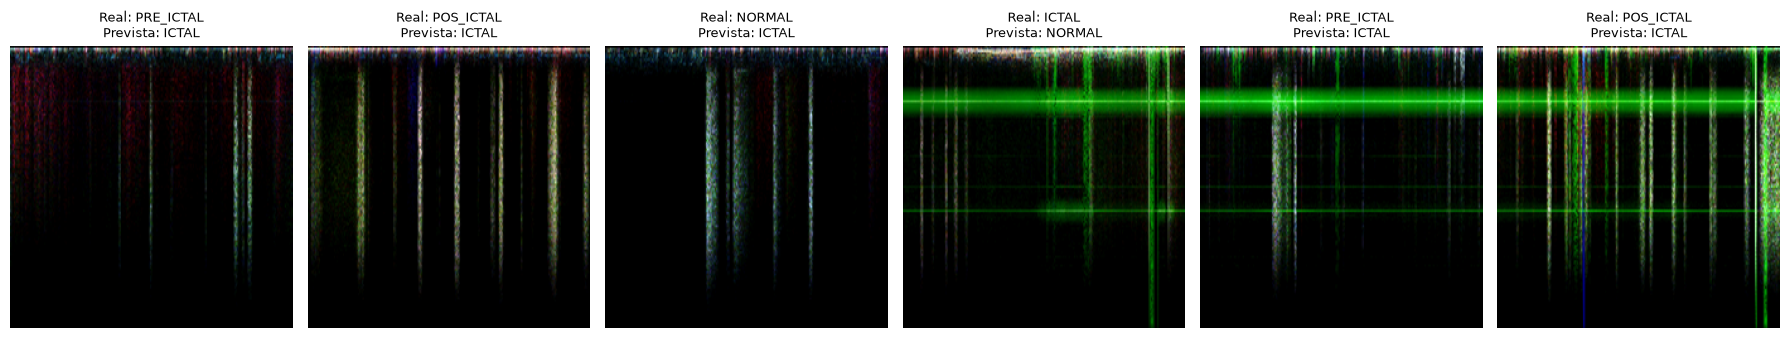

In [8]:
analise_erros(prob_cnn)

### Respostas (CNN)

Matriz de confusão (linhas = classe real, colunas = classe prevista):

| Real \ Prevista | ICTAL | NORMAL | POS_ICTAL | PRE_ICTAL |
|---|---|---|---|---|
| ICTAL | **1** | 2 | 0 | 2 |
| NORMAL | 3 | **1** | 0 | 1 |
| POS_ICTAL | 3 | 1 | **0** | 1 |
| PRE_ICTAL | 3 | 2 | 0 | **0** |

**Qual classe apresentou o maior desempenho?**
NORMAL, com F1 de 0,18 (precisão 0,17 e recall 0,20). Mesmo assim é bem baixo: acertou só 1 das 5 imagens.

**Qual classe apresentou maior dificuldade de classificação?**
POS_ICTAL e PRE_ICTAL, as duas com F1 = 0. Nenhuma imagem dessas classes foi acertada, e POS_ICTAL nunca foi prevista.

**Quais classes apresentaram maior número de acertos?**
ICTAL e NORMAL, com 1 acerto cada. No total foram 2 acertos em 20 imagens (10% de acurácia, abaixo dos 25% do acaso).

**Quais classes foram mais confundidas?**
O modelo previu ICTAL para quase tudo: foram 9 falsos positivos de ICTAL (3 de NORMAL, 3 de POS_ICTAL e 3 de PRE_ICTAL). As imagens ICTAL foram previstas como NORMAL (2) e PRE_ICTAL (2).

**Existe uma classe particularmente difícil para o modelo?**
POS_ICTAL, que teve recall 0 e não foi prevista nenhuma vez. PRE_ICTAL também ficou com recall 0.

**O modelo apresenta boa capacidade de separação entre as classes?**
Não. O ROC-AUC global é 0,50, o mesmo de um classificador aleatório. Em ICTAL o ROC-AUC é 0,31, abaixo do acaso, então o modelo dá mais probabilidade de ICTAL para imagens que não são ICTAL. POS_ICTAL tem 0,69, mas essa probabilidade nunca é a maior das quatro, então não vira acerto.

**As curvas indicam desempenho consistente?**
Não. As curvas ROC ficam em cima ou abaixo da diagonal, e o PR-AUC global (0,35) é próximo da proporção de cada classe no teste (0,25). Isso bate com o overfitting do notebook 05: 98% no treino, 30% na validação e 10% no teste.

**Análise dos erros (falsos positivos, falsos negativos e casos ambíguos):**
- 18 das 20 imagens foram classificadas errado, quase sempre com muita confiança (diferença de 0,7 a 1,0 entre as duas maiores probabilidades). O modelo continua confiante mesmo errando, o que combina com overfitting.
- Falsos positivos: ICTAL 9, NORMAL 5 e PRE_ICTAL 4.
- Falsos negativos: POS_ICTAL e PRE_ICTAL erraram as 5 imagens; ICTAL e NORMAL erraram 4.
- Por paciente: no PN13, 9 de 12 imagens foram previstas como ICTAL, independente da classe real, e no PN17 as previsões ficaram entre NORMAL e PRE_ICTAL. Parece que o modelo responde mais ao paciente do que à fase da crise.
- Casos ambíguos: só 3 (imagens 1, 5 e 8). Nas imagens 1 e 5 (PRE_ICTAL do PN13) a dúvida foi entre ICTAL e POS_ICTAL, e a imagem 8 ficou entre ICTAL (0,45) e NORMAL (0,55).

# 2. FCNN

In [9]:
prob_fcnn = prever('modelo_fcnn.keras')
pred_fcnn = np.argmax(prob_fcnn, axis=1)

W0000 00:00:1795092378.243956   56967 cpu_allocator_impl.cc:82] Allocation of 80281600 exceeds 10% of free system memory.


## Acurácia, Precisão, Recall e F1-Score

In [10]:
metricas(pred_fcnn)

              precision    recall  f1-score   support

       ICTAL       0.00      0.00      0.00         5
      NORMAL       0.33      0.40      0.36         5
   POS_ICTAL       0.40      0.80      0.53         5
   PRE_ICTAL       0.50      0.40      0.44         5

    accuracy                           0.40        20
   macro avg       0.31      0.40      0.34        20
weighted avg       0.31      0.40      0.34        20



,precision,recall,f1-score,support
ICTAL,0.00,0.0,0.00,5.0
NORMAL,0.33,0.4,0.36,5.0
POS_ICTAL,0.40,0.8,0.53,5.0
PRE_ICTAL,0.50,0.4,0.44,5.0
accuracy,0.40,0.4,0.40,0.4
macro avg,0.31,0.4,0.34,20.0
weighted avg,0.31,0.4,0.34,20.0


## Matriz de confusão

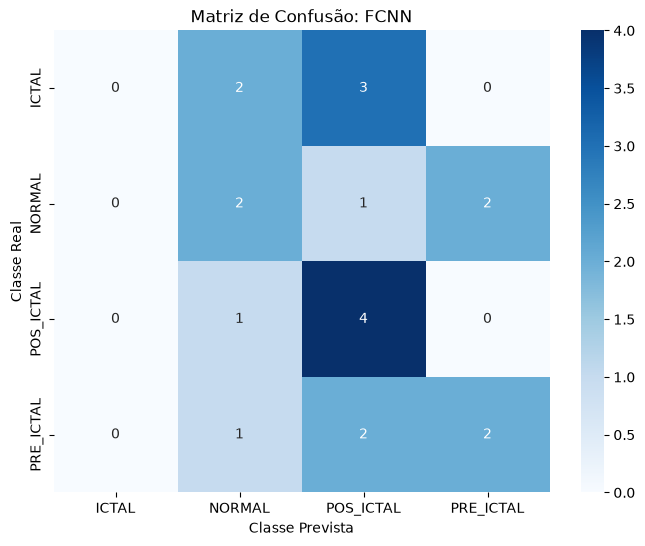

In [11]:
matriz_confusao(pred_fcnn, 'FCNN')

## Curvas ROC e Precision-Recall

ROC-AUC global: 0.64
PR-AUC global:  0.4666


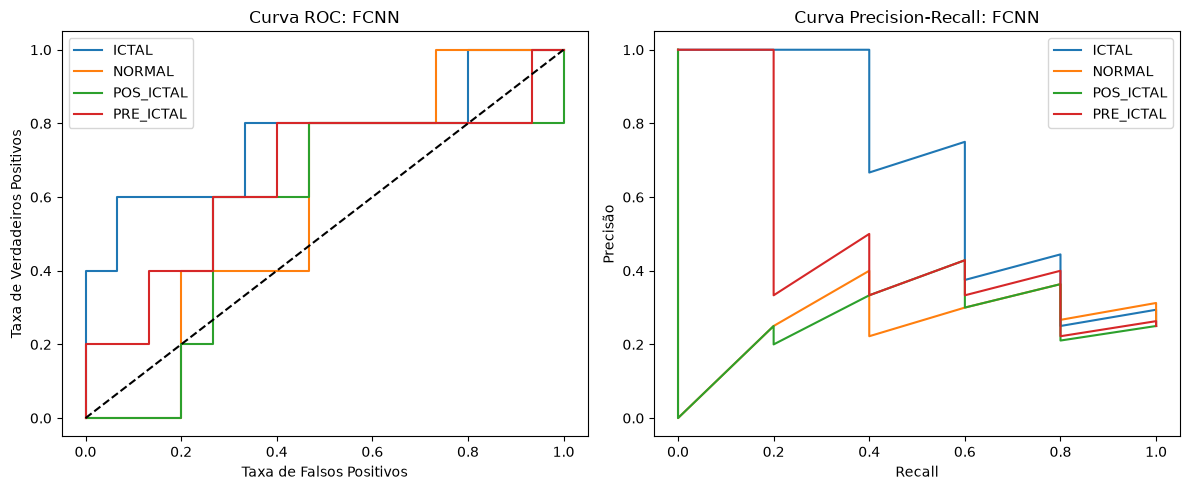

,ROC-AUC,PR-AUC
ICTAL,0.76,0.70
NORMAL,0.59,0.33
POS_ICTAL,0.56,0.33
PRE_ICTAL,0.65,0.52


In [12]:
curvas_roc_pr(prob_fcnn, 'FCNN')

## Análise sistemática dos erros

Imagens classificadas incorretamente: 12 de 20


,arquivo,real,prevista,ICTAL,NORMAL,POS_ICTAL,PRE_ICTAL,diferenca_top2
0,PN13-1_seizure01_ictal.png,ICTAL,POS_ICTAL,0.20,0.18,0.39,0.24,0.15
1,PN13-1_seizure01_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.19,0.14,0.51,0.16,0.32
4,PN13-2_seizure02_ictal.png,ICTAL,NORMAL,0.07,0.60,0.07,0.25,0.35
5,PN13-2_seizure02_pre_ictal.png,PRE_ICTAL,NORMAL,0.07,0.58,0.08,0.26,0.32
6,PN13-2_seizure02_pos_ictal.png,POS_ICTAL,NORMAL,0.04,0.78,0.03,0.15,0.62
8,PN13-3_seizure03_ictal.png,ICTAL,NORMAL,0.22,0.28,0.23,0.26,0.01
9,PN13-3_seizure03_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.18,0.22,0.32,0.29,0.03
11,PN13-3_seizure03_normal.png,NORMAL,PRE_ICTAL,0.16,0.24,0.28,0.33,0.05
12,PN17-1_seizure01_ictal.png,ICTAL,POS_ICTAL,0.17,0.20,0.33,0.29,0.04
15,PN17-1_seizure01_normal.png,NORMAL,PRE_ICTAL,0.14,0.23,0.29,0.33,0.04


Falsos Positivos e Falsos Negativos por classe:


,Falsos Positivos,Falsos Negativos
ICTAL,0,5
NORMAL,4,3
POS_ICTAL,6,1
PRE_ICTAL,2,3


Casos ambíguos (diferença entre as duas maiores probabilidades < 0.15):


,arquivo,real,prevista,ICTAL,NORMAL,POS_ICTAL,PRE_ICTAL,diferenca_top2
2,PN13-1_seizure01_pos_ictal.png,POS_ICTAL,POS_ICTAL,0.19,0.26,0.36,0.19,0.10
3,PN13-1_seizure01_normal.png,NORMAL,NORMAL,0.16,0.30,0.26,0.28,0.02
8,PN13-3_seizure03_ictal.png,ICTAL,NORMAL,0.22,0.28,0.23,0.26,0.01
9,PN13-3_seizure03_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.18,0.22,0.32,0.29,0.03
10,PN13-3_seizure03_pos_ictal.png,POS_ICTAL,POS_ICTAL,0.17,0.21,0.38,0.24,0.14
11,PN13-3_seizure03_normal.png,NORMAL,PRE_ICTAL,0.16,0.24,0.28,0.33,0.05
12,PN17-1_seizure01_ictal.png,ICTAL,POS_ICTAL,0.17,0.20,0.33,0.29,0.04
13,PN17-1_seizure01_pre_ictal.png,PRE_ICTAL,PRE_ICTAL,0.15,0.19,0.32,0.34,0.01
14,PN17-1_seizure01_pos_ictal.png,POS_ICTAL,POS_ICTAL,0.17,0.27,0.30,0.26,0.03
15,PN17-1_seizure01_normal.png,NORMAL,PRE_ICTAL,0.14,0.23,0.29,0.33,0.04


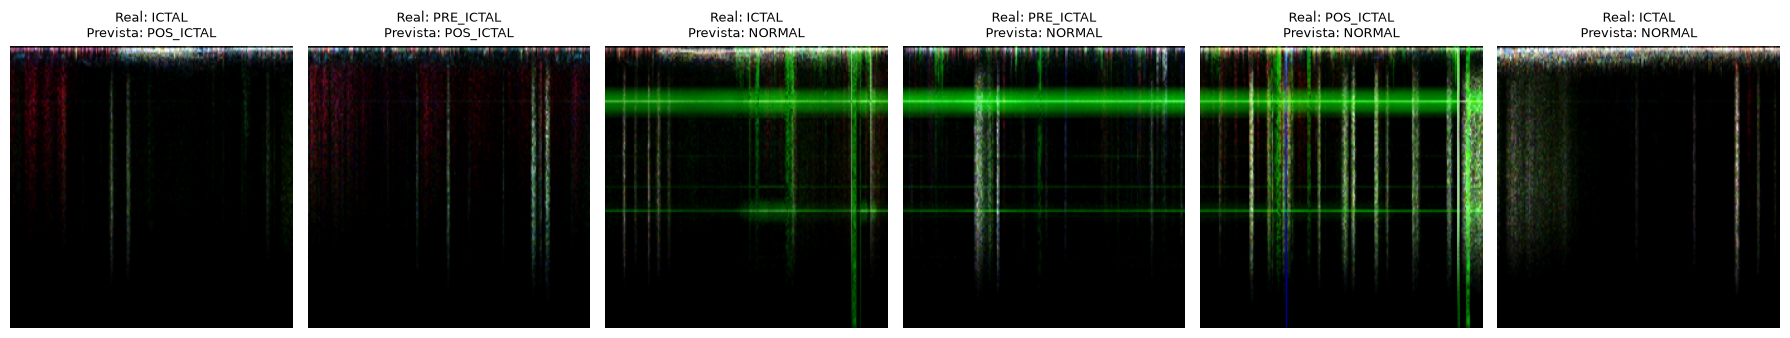

In [13]:
analise_erros(prob_fcnn)

### Respostas (FCNN)

Matriz de confusão (linhas = classe real, colunas = classe prevista):

| Real \ Prevista | ICTAL | NORMAL | POS_ICTAL | PRE_ICTAL |
|---|---|---|---|---|
| ICTAL | **0** | 2 | 3 | 0 |
| NORMAL | 0 | **2** | 1 | 2 |
| POS_ICTAL | 0 | 1 | **4** | 0 |
| PRE_ICTAL | 0 | 1 | 2 | **2** |

**Qual classe apresentou o maior desempenho?**
POS_ICTAL, com F1 de 0,53 e recall de 0,80 (acertou 4 de 5). Depois vem PRE_ICTAL, com F1 de 0,44 e a maior precisão (0,50).

**Qual classe apresentou maior dificuldade de classificação?**
ICTAL, com F1 = 0. Nenhuma das 5 imagens foi acertada, e o modelo não previu ICTAL nenhuma vez.

**Quais classes apresentaram maior número de acertos?**
POS_ICTAL com 4 acertos, depois NORMAL e PRE_ICTAL com 2 cada. Foram 8 acertos em 20 (40% de acurácia).

**Quais classes foram mais confundidas?**
POS_ICTAL virou a resposta mais comum do modelo e recebeu 6 falsos positivos (3 de ICTAL, 2 de PRE_ICTAL e 1 de NORMAL). ICTAL foi confundida com POS_ICTAL (3) e NORMAL (2), e NORMAL com PRE_ICTAL (2).

**Existe uma classe particularmente difícil para o modelo?**
Sim, ICTAL, com recall 0. Mesmo assim ela tem o melhor ROC-AUC (0,76): a probabilidade de ICTAL é maior nas imagens ICTAL do que nas outras, só que nunca chega a ser a maior das quatro. Mudar o limiar de decisão poderia recuperar alguns desses acertos.

**O modelo apresenta boa capacidade de separação entre as classes?**
Moderada. O ROC-AUC global é 0,64 e o PR-AUC é 0,47, acima do acaso (0,50 e 0,25). Por classe: ICTAL 0,76, PRE_ICTAL 0,65, NORMAL 0,59 e POS_ICTAL 0,56.

**As curvas indicam desempenho consistente?**
Em parte. As curvas ROC ficam acima da diagonal, principalmente a de ICTAL, mas com só 5 positivos por classe elas andam em degraus e uma única imagem já muda bastante a curva. A acurácia de teste (40%) é parecida com a de validação (35%), então o modelo não decorou o treino; o problema dele é underfitting.

**Análise dos erros (falsos positivos, falsos negativos e casos ambíguos):**
- 12 das 20 imagens foram classificadas errado.
- Falsos positivos: POS_ICTAL 6, NORMAL 4, PRE_ICTAL 2 e ICTAL 0.
- Falsos negativos: ICTAL errou as 5; NORMAL e PRE_ICTAL erraram 3; POS_ICTAL só 1.
- Casos ambíguos: 14 das 20 imagens têm diferença menor que 0,15 entre as duas maiores probabilidades, incluindo 6 acertos. Quase todas as probabilidades ficam entre 0,15 e 0,40, então o modelo tem pouca confiança no que prevê, o que bate com o underfitting do treino.
- Os erros com mais confiança foram as imagens 4, 5 e 6 (PN13, crise 02), todas previstas como NORMAL com probabilidade entre 0,58 e 0,78. Imagens da mesma gravação são parecidas e acabam caindo na mesma classe.

# 3. Encoder-Decoder

In [14]:
prob_encdec = prever('modelo_encdec.keras')
pred_encdec = np.argmax(prob_encdec, axis=1)

W0000 00:00:1795092379.499926   56968 cpu_allocator_impl.cc:82] Allocation of 96393216 exceeds 10% of free system memory.


## Acurácia, Precisão, Recall e F1-Score

In [15]:
metricas(pred_encdec)

              precision    recall  f1-score   support

       ICTAL       1.00      0.40      0.57         5
      NORMAL       0.00      0.00      0.00         5
   POS_ICTAL       0.28      1.00      0.43         5
   PRE_ICTAL       0.00      0.00      0.00         5

    accuracy                           0.35        20
   macro avg       0.32      0.35      0.25        20
weighted avg       0.32      0.35      0.25        20



,precision,recall,f1-score,support
ICTAL,1.00,0.40,0.57,5.00
NORMAL,0.00,0.00,0.00,5.00
POS_ICTAL,0.28,1.00,0.43,5.00
PRE_ICTAL,0.00,0.00,0.00,5.00
accuracy,0.35,0.35,0.35,0.35
macro avg,0.32,0.35,0.25,20.00
weighted avg,0.32,0.35,0.25,20.00


## Matriz de confusão

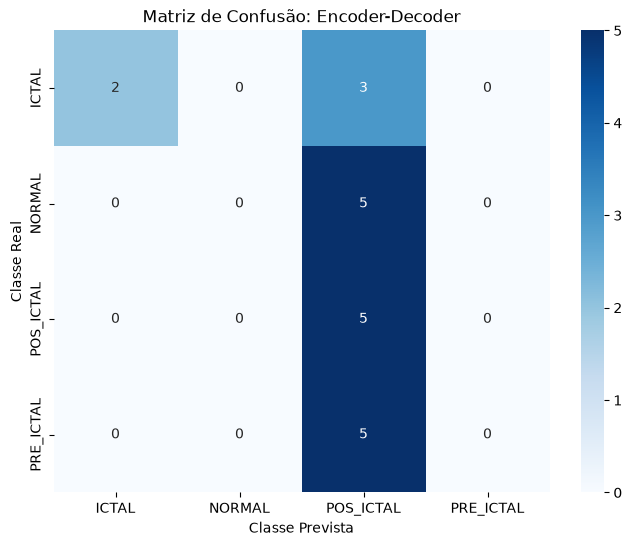

In [16]:
matriz_confusao(pred_encdec, 'Encoder-Decoder')

## Curvas ROC e Precision-Recall

ROC-AUC global: 0.71
PR-AUC global:  0.531


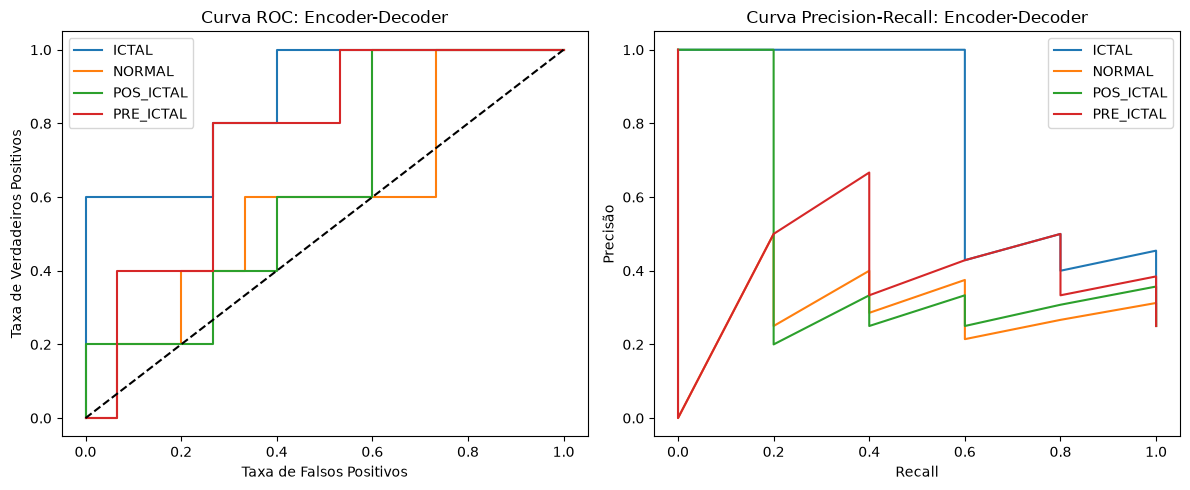

,ROC-AUC,PR-AUC
ICTAL,0.87,0.79
NORMAL,0.59,0.37
POS_ICTAL,0.63,0.47
PRE_ICTAL,0.76,0.50


In [17]:
curvas_roc_pr(prob_encdec, 'Encoder-Decoder')

## Análise sistemática dos erros

Imagens classificadas incorretamente: 13 de 20


,arquivo,real,prevista,ICTAL,NORMAL,POS_ICTAL,PRE_ICTAL,diferenca_top2
0,PN13-1_seizure01_ictal.png,ICTAL,POS_ICTAL,0.24,0.24,0.27,0.24,0.03
1,PN13-1_seizure01_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.21,0.25,0.28,0.26,0.02
3,PN13-1_seizure01_normal.png,NORMAL,POS_ICTAL,0.22,0.25,0.28,0.26,0.02
4,PN13-2_seizure02_ictal.png,ICTAL,POS_ICTAL,0.23,0.24,0.28,0.25,0.03
5,PN13-2_seizure02_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.21,0.25,0.28,0.26,0.03
7,PN13-2_seizure02_normal.png,NORMAL,POS_ICTAL,0.22,0.24,0.28,0.25,0.03
9,PN13-3_seizure03_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.23,0.24,0.28,0.25,0.02
11,PN13-3_seizure03_normal.png,NORMAL,POS_ICTAL,0.21,0.25,0.28,0.27,0.01
12,PN17-1_seizure01_ictal.png,ICTAL,POS_ICTAL,0.22,0.24,0.28,0.26,0.02
13,PN17-1_seizure01_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.20,0.25,0.28,0.27,0.00


Falsos Positivos e Falsos Negativos por classe:


,Falsos Positivos,Falsos Negativos
ICTAL,0,3
NORMAL,0,5
POS_ICTAL,13,0
PRE_ICTAL,0,5


Casos ambíguos (diferença entre as duas maiores probabilidades < 0.15):


,arquivo,real,prevista,ICTAL,NORMAL,POS_ICTAL,PRE_ICTAL,diferenca_top2
0,PN13-1_seizure01_ictal.png,ICTAL,POS_ICTAL,0.24,0.24,0.27,0.24,0.03
1,PN13-1_seizure01_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.21,0.25,0.28,0.26,0.02
2,PN13-1_seizure01_pos_ictal.png,POS_ICTAL,POS_ICTAL,0.24,0.25,0.28,0.24,0.03
3,PN13-1_seizure01_normal.png,NORMAL,POS_ICTAL,0.22,0.25,0.28,0.26,0.02
4,PN13-2_seizure02_ictal.png,ICTAL,POS_ICTAL,0.23,0.24,0.28,0.25,0.03
5,PN13-2_seizure02_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.21,0.25,0.28,0.26,0.03
6,PN13-2_seizure02_pos_ictal.png,POS_ICTAL,POS_ICTAL,0.20,0.25,0.29,0.25,0.04
7,PN13-2_seizure02_normal.png,NORMAL,POS_ICTAL,0.22,0.24,0.28,0.25,0.03
8,PN13-3_seizure03_ictal.png,ICTAL,ICTAL,0.27,0.24,0.27,0.22,0.00
9,PN13-3_seizure03_pre_ictal.png,PRE_ICTAL,POS_ICTAL,0.23,0.24,0.28,0.25,0.02


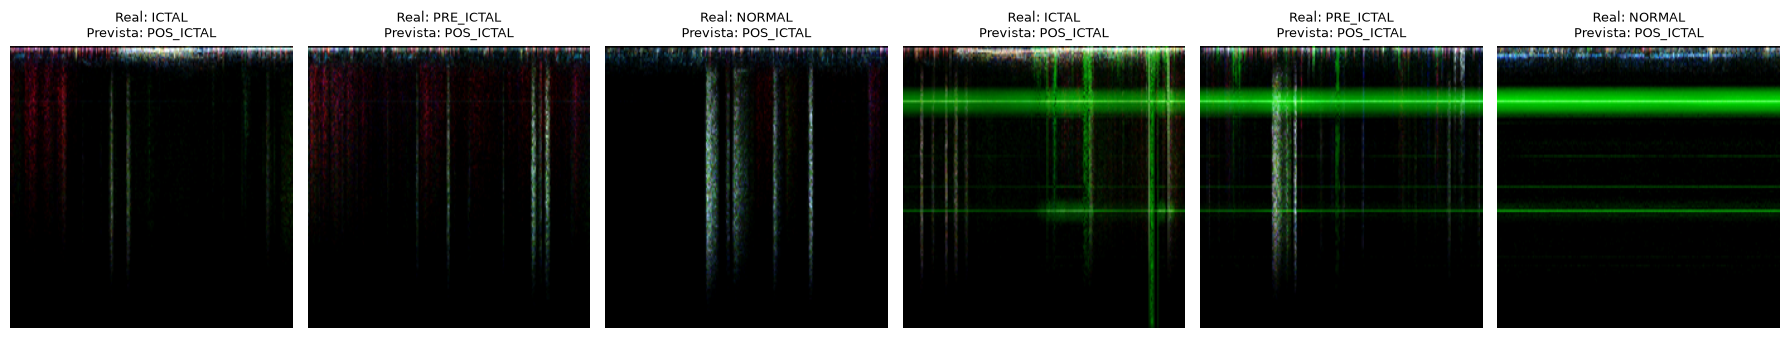

In [18]:
analise_erros(prob_encdec)

### Respostas (Encoder-Decoder)

Matriz de confusão (linhas = classe real, colunas = classe prevista):

| Real \ Prevista | ICTAL | NORMAL | POS_ICTAL | PRE_ICTAL |
|---|---|---|---|---|
| ICTAL | **2** | 0 | 3 | 0 |
| NORMAL | 0 | **0** | 5 | 0 |
| POS_ICTAL | 0 | 0 | **5** | 0 |
| PRE_ICTAL | 0 | 0 | 5 | **0** |

**Qual classe apresentou o maior desempenho?**
ICTAL, com F1 de 0,57. O modelo só previu ICTAL duas vezes e acertou as duas (precisão 1,00), mas deixou passar 3 das 5 imagens (recall 0,40). POS_ICTAL teve recall de 1,00, mas só porque o modelo prevê POS_ICTAL para quase tudo (precisão 0,28).

**Qual classe apresentou maior dificuldade de classificação?**
NORMAL e PRE_ICTAL, as duas com F1 = 0. Nenhuma das duas foi prevista nenhuma vez.

**Quais classes apresentaram maior número de acertos?**
POS_ICTAL (5) e ICTAL (2). Foram 7 acertos em 20 (35% de acurácia).

**Quais classes foram mais confundidas?**
Tudo foi parar em POS_ICTAL: as 5 imagens NORMAL, as 5 PRE_ICTAL e 3 das 5 ICTAL foram previstas como POS_ICTAL. São 13 falsos positivos numa classe só.

**Existe uma classe particularmente difícil para o modelo?**
NORMAL e PRE_ICTAL, com recall 0. Na prática, o modelo responde POS_ICTAL por padrão e só sai disso em duas imagens ICTAL.

**O modelo apresenta boa capacidade de separação entre as classes?**
Pela ordenação das probabilidades, sim, até mais que a FCNN: ROC-AUC global de 0,71 e PR-AUC de 0,53. Por classe: ICTAL 0,87, PRE_ICTAL 0,76, POS_ICTAL 0,63 e NORMAL 0,59. O problema é que as probabilidades são quase iguais e a de POS_ICTAL fica sempre um pouco acima das outras, então essa ordenação quase nunca vira acerto.

**As curvas indicam desempenho consistente?**
Não muito. As curvas ROC ficam acima da diagonal em todas as classes, e a de ICTAL é a melhor dos três modelos. Mas todas as probabilidades ficam entre 0,20 e 0,29, então diferenças de centésimos decidem a ordenação, e com 5 positivos por classe isso pode mudar bastante com outra amostra.

**Análise dos erros (falsos positivos, falsos negativos e casos ambíguos):**
- 13 das 20 imagens foram classificadas errado.
- Falsos positivos: todos em POS_ICTAL (13); as outras classes têm 0.
- Falsos negativos: NORMAL e PRE_ICTAL erraram as 5; ICTAL errou 3; POS_ICTAL nenhuma.
- Casos ambíguos: as 20 imagens. A maior diferença entre as duas maiores probabilidades é 0,04, e várias ficam em 0,00. A saída é quase uniforme (cerca de 0,25 por classe), o que confirma o treino: a loss ficou perto de ln 4 ≈ 1,386 e a rede quase não aprendeu.

# Comparação entre os modelos

## Arquiteturas e comportamento no treino

| Modelo | Camadas convolucionais | Camadas densas | Parâmetros |
|---|---|---|---|
| CNN | 3 `Conv2D` | 2 `Dense` | 11.169.476 |
| FCNN | 4 `Conv2D` (a última 1x1) | nenhuma | 23.844 |
| Encoder-Decoder | 2 `Conv2D` + 2 `Conv2DTranspose` | 1 `Dense` | 19.028 |

Quase todos os parâmetros da CNN estão na `Dense` que vem depois do `Flatten`. Trocar essa parte por `GlobalAveragePooling2D` (FCNN e Encoder-Decoder) deixa o modelo mais de 400 vezes menor.

Comportamento no treino (notebooks 05):

| Modelo | Acurácia de treino (final) | Acurácia de validação (final) | Melhor validação | Diagnóstico |
|---|---|---|---|---|
| CNN | 98% | 30% | 50% | Overfitting |
| FCNN | 32% | 35% | 40% | Underfitting |
| Encoder-Decoder | 29% | 25% | 40% | Quase não aprendeu (saída quase uniforme) |

A CNN é a única que aprende o conjunto de treino, mas decora em vez de generalizar. As duas redes menores ficam perto do acaso (25%) já no treino. Nenhuma das três generaliza bem com só 100 imagens de treino. Além disso, os pacientes de validação (PN09, PN16) e de teste (PN13, PN17) não aparecem no treino, então o modelo precisa acertar em pacientes que nunca viu.

## Métricas no conjunto de teste

Precisão, Recall e F1-Score são a média das 4 classes (*macro*). Quanto mais escura a célula, melhor o valor naquela coluna.

In [19]:
probabilidades = {'CNN': prob_cnn, 'FCNN': prob_fcnn, 'Encoder-Decoder': prob_encdec}

linhas = []
for nome, prob in probabilidades.items():
    pred = np.argmax(prob, axis=1)
    linhas.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_true, pred),
        'Precisão': precision_score(y_true, pred, average='macro', zero_division=0),
        'Recall': recall_score(y_true, pred, average='macro', zero_division=0),
        'F1-Score': f1_score(y_true, pred, average='macro', zero_division=0),
        'ROC-AUC': roc_auc_score(y_true_bin, prob, multi_class='ovr'),
        'PR-AUC': average_precision_score(y_true_bin, prob),
    })

comparacao = pd.DataFrame(linhas).set_index('Modelo').round(2)
comparacao.style.background_gradient(cmap='Blues', axis=0).format('{:.2f}')

,Acurácia,Precisão,Recall,F1-Score,ROC-AUC,PR-AUC
Modelo,,,,,,
CNN,0.10,0.07,0.10,0.08,0.50,0.35
FCNN,0.40,0.31,0.40,0.34,0.64,0.47
Encoder-Decoder,0.35,0.32,0.35,0.25,0.71,0.53


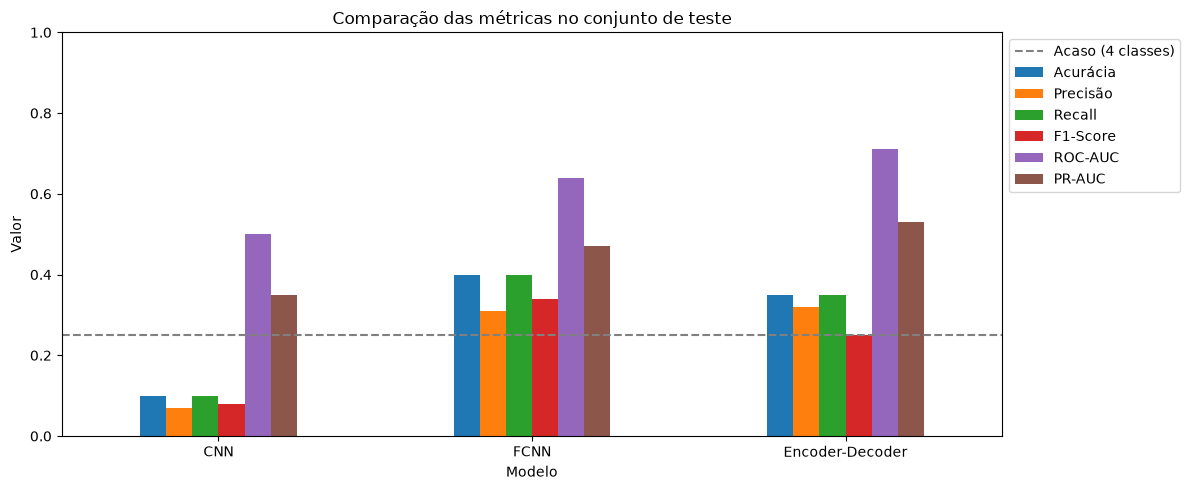

In [20]:
comparacao.plot(kind='bar', figsize=(12, 5), rot=0)
plt.title('Comparação das métricas no conjunto de teste')
plt.ylabel('Valor')
plt.ylim(0, 1)
plt.axhline(0.25, color='gray', linestyle='--', label='Acaso (4 classes)')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

### Conclusão

| Modelo | Acurácia | Precisão | Recall | F1-Score | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| CNN | 0,10 | 0,07 | 0,10 | 0,08 | 0,50 | 0,35 |
| FCNN | **0,40** | 0,31 | **0,40** | **0,34** | 0,64 | 0,47 |
| Encoder-Decoder | 0,35 | **0,32** | 0,35 | 0,25 | **0,71** | **0,53** |

**Qual modelo teve o melhor desempenho geral?**
A FCNN, por pouco. Ela tem a maior acurácia (40%) e o maior F1 macro (0,34), e foi a única que acertou imagens de três classes diferentes. O Encoder-Decoder ficou com o melhor ROC-AUC (0,71) e PR-AUC (0,53), então ordena melhor as probabilidades, mas na hora de escolher a classe ele prevê POS_ICTAL para 18 das 20 imagens e o F1 cai para 0,25. Os dois modelos pequenos (cerca de 20 mil parâmetros) foram melhores que a CNN de 11 milhões: com tão poucos dados, o modelo grande só decora o treino.

**Algum modelo ficou claramente acima do acaso (25% de acurácia)?**
Não de forma clara. A FCNN fez 40% e o Encoder-Decoder 35%, que são 8 e 7 acertos contra 5 esperados por acaso. Com 20 imagens, essa diferença pode ser sorte. O ROC-AUC de 0,71 do Encoder-Decoder, principalmente em ICTAL (0,87), é o sinal mais forte de que as previsões carregam alguma informação. A CNN ficou abaixo do acaso (10%), mesmo com 98% no treino.

**Limitações e próximos passos**
- Poucos dados: 100 imagens de treino e 20 de teste (5 por classe). Cada imagem de teste vale 5 pontos de acurácia, então as diferenças entre os modelos têm muita incerteza.
- Pacientes novos no teste: PN13 e PN17 não aparecem no treino. A CNN mostrou viés por paciente (quase tudo do PN13 virou ICTAL), o que indica que ela aprendeu características de cada pessoa e não da fase da crise.
- O que dá para melhorar: data augmentation, `EarlyStopping` na CNN (a menor `val_loss` foi na época 8), mais épocas para a FCNN e o Encoder-Decoder (a loss de validação do Encoder-Decoder ainda estava caindo na época 30), transfer learning com uma rede pré-treinada (VGG16 ou ResNet, por exemplo) e validação cruzada por paciente.